# Taller de Fundamentos de Machine Learning
## Representación, espacios métricos y aprendizaje no supervisado de municipios colombianos

**Objetivo.** Representar municipios colombianos a partir de variables demográficas, socioeconómicas, educativas, de seguridad, ambientales, turísticas e institucionales para identificar similitudes y grupos mediante espacios métricos y aprendizaje no supervisado.

**Pregunta de trabajo.** ¿Qué municipios presentan condiciones similares para vivir y desarrollarse considerando conjuntamente estas dimensiones?

Los resultados describen similitud estadística entre municipios y no implican relaciones causales.


## 1. Carga de datos

Se cargan la base municipal y las hojas de soporte del Excel para trabajar con los datos, el diccionario de variables y la trazabilidad de fuentes.


In [23]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import cdist
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
import ipywidgets as widgets

RANDOM_STATE = 42

sns.set_theme(style='whitegrid', palette='colorblind')
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 90)
warnings.filterwarnings('ignore', category=FutureWarning)

URL_EXCEL = (
    "https://raw.githubusercontent.com/"
    "stevenpeinado/Municipios_ML/main/base_municipios_colombia_ml.xlsx"
)

hojas = pd.read_excel(
    URL_EXCEL,
    sheet_name=None,
    header=3,
    dtype={'codigo_municipio': str}
)

esperadas = {
    'datos_finales',
    'diccionario_variables',
    'fuentes',
    'calidad_datos'
}

assert esperadas.issubset(hojas), (
    f'Faltan hojas: {esperadas - set(hojas)}'
)

datos = hojas['datos_finales'].copy()
diccionario = hojas['diccionario_variables'].dropna(
    subset=['variable']
).copy()
fuentes = hojas['fuentes'].dropna(
    subset=['institucion']
).copy()
calidad = hojas['calidad_datos'].dropna(
    subset=['variable']
).copy()

datos['codigo_municipio'] = (
    datos['codigo_municipio']
    .astype(str)
    .str.zfill(5)
)

print('Hojas:', list(hojas))
print('Dimensiones de datos_finales:', datos.shape)

display(datos.head(3))

Hojas: ['datos_finales', 'diccionario_variables', 'fuentes', 'calidad_datos']
Dimensiones de datos_finales: (200, 32)


,codigo_municipio,municipio,departamento,latitud,longitud,area_km2,poblacion_total_2023,densidad_hab_km2_2023,pobreza_multidimensional_pct_2018,nbi_pct_2018,ingresos_propios_percapita_millones_2023,internet_fijo_por_100_hab_2023t3,resultado_servicios_publicos_mdm_2023,cobertura_neta_educacion_pct_2024,cobertura_bruta_educacion_pct_2024,desercion_escolar_pct_2024,homicidios_por_100k_2024,temperatura_media_c_2023,precipitacion_anual_mm_2023,establecimientos_turisticos_por_10k_2026,camas_turisticas_por_10k_2026,resultado_educacion_mdm_2023,resultado_salud_mdm_2023,resultado_seguridad_mdm_2023,desempeno_municipal_2023,desempeno_institucional_prom_2020_2023,desempeno_fiscal_prom_2020_2023,irca_2023,incidencia_conflicto_armado_2022,es_capital,es_ciudad_intermedia,categoria_ruralidad_2023
0,91001,LETICIA,AMAZONAS,-3.396643,-70.179690,6183.129180,54110,8.751232,48.4,27.357347,0.402668,1.598595,37.089707,88.17,103.51,5.61,38.809832,25.970219,2214.10,14.784698,516.909998,45.980901,90.368499,88.752258,59.020615,45.562267,57.153227,23.188095,12.058119,1,0,Rural
1,05034,ANDES,ANTIOQUIA,5.639637,-75.916944,402.502562,45796,113.778158,40.1,12.288330,0.301723,7.612019,35.529409,77.30,86.05,4.33,43.671936,18.086493,2047.74,2.401957,91.711066,49.920865,94.132697,85.966413,62.044058,45.564167,58.335393,4.716886,6.923309,0,0,Intermedio
2,05045,APARTADÓ,ANTIOQUIA,7.890687,-76.586774,535.180051,130362,243.585313,28.0,14.674010,0.415354,15.967843,68.146667,88.46,102.55,4.80,25.314125,26.342658,3286.88,5.446372,139.687946,57.411178,93.002936,87.307654,71.811606,64.535233,55.905616,0,6.465412,0,1,Ciudades y aglomeraciones


**Resultado.** La base contiene 200 municipios y 32 columnas, con indicadores de distintos años entre 2018 y 2026. Por ello se interpreta como una caracterización multidimensional reciente y no como una fotografía de un único año.


## 2. Requisitos y variables de análisis

Se verifica que la base cumpla el mínimo de municipios, atributos y fuentes exigido por el taller, y se definen las 18 variables que formarán la representación de cada municipio.


In [2]:
variables = [
    'poblacion_total_2023', 'densidad_hab_km2_2023',
    'pobreza_multidimensional_pct_2018',
    'ingresos_propios_percapita_millones_2023',
    'internet_fijo_por_100_hab_2023t3',
    'resultado_servicios_publicos_mdm_2023',
    'cobertura_neta_educacion_pct_2024', 'desercion_escolar_pct_2024',
    'homicidios_por_100k_2024', 'resultado_seguridad_mdm_2023',
    'temperatura_media_c_2023', 'precipitacion_anual_mm_2023',
    'establecimientos_turisticos_por_10k_2026',
    'camas_turisticas_por_10k_2026', 'desempeno_municipal_2023',
    'desempeno_fiscal_prom_2020_2023', 'irca_2023',
    'incidencia_conflicto_armado_2022'
]
assert len(variables) == 18 and len(set(variables)) == 18
faltan_columnas = sorted(set(variables) - set(datos.columns))
assert not faltan_columnas, f'Nombres de columnas distintos: {faltan_columnas}'
assert set(variables).issubset(set(diccionario['variable']))
assert len(datos) >= 100 and len(variables) >= 15
assert fuentes['institucion'].nunique() >= 3
assert datos['codigo_municipio'].is_unique

print(f"Municipios: {len(datos)} | Columnas: {datos.shape[1]} | "
      f"Atributos de representación: {len(variables)} | "
      f"Instituciones identificadas: {fuentes['institucion'].nunique()}")
display(fuentes[['institucion', 'conjunto', 'periodo', 'enlace']])
display(diccionario.loc[diccionario['variable'].isin(variables),
                        ['variable', 'definicion', 'unidad', 'fuente', 'anio_corte', 'notas']])

Municipios: 200 | Columnas: 32 | Atributos de representación: 18 | Instituciones identificadas: 6


,institucion,conjunto,periodo,enlace
0,DNP,Tipologías de Entidades Territoriales 2025 – base municipal,2020–2025,https://colaboracion.dnp.gov.co/CDT/Desarrollo%20Territorial/Desempeno_Fiscal/5.%20Bas...
1,DNP,Feature Service de municipios,2026,https://gis.dnp.gov.co/server/rest/services/osc/territorios/FeatureServer/4
2,MinTIC,Internet Fijo Accesos por tecnología y segmento,2023 T3,https://www.datos.gov.co/d/n48w-gutb
3,Ministerio de Educación Nacional,Estadísticas de educación por municipio,2024,https://www.datos.gov.co/d/nudc-7mev
4,Policía Nacional,Homicidio,2024,https://www.datos.gov.co/d/m8fd-ahd9
5,MinCIT,Registro Nacional de Turismo – RNT,2026,https://www.datos.gov.co/d/thwd-ivmp
6,NASA,POWER Daily API,2023,https://power.larc.nasa.gov/docs/services/api/temporal/daily/


,variable,definicion,unidad,fuente,anio_corte,notas
6,poblacion_total_2023,Población total proyectada,Personas,DNP / DANE,2023,NaN
7,densidad_hab_km2_2023,Población dividida por área,Habitantes/km²,Cálculo propio con DNP/DANE,2023,NaN
8,pobreza_multidimensional_pct_2018,Incidencia de pobreza multidimensional censal,Porcentaje,DANE vía DNP,2018,NaN
10,ingresos_propios_percapita_millones_2023,Ingresos tributarios municipales por habitante,Millones COP por habitante,DNP,2023,Proxy económico; sustituye valor agregado por habitante por disponibilidad nacional re...
11,internet_fijo_por_100_hab_2023t3,Accesos de internet fijo por 100 habitantes,Accesos/100 habitantes,MinTIC / Datos Abiertos Colombia,2023 T3,Suma de accesos reportados dividida por población 2023.
12,resultado_servicios_publicos_mdm_2023,Componente de resultados de servicios públicos de la MDM,Puntaje 0–100,DNP,2023,Proxy conjunto; no equivale a coberturas separadas de acueducto y alcantarillado.
13,cobertura_neta_educacion_pct_2024,"Cobertura neta total en preescolar, básica y media",Porcentaje,Ministerio de Educación Nacional,2024,NaN
15,desercion_escolar_pct_2024,Tasa de deserción escolar,Porcentaje,Ministerio de Educación Nacional,2024,NaN
16,homicidios_por_100k_2024,Homicidios por cada 100.000 habitantes,Casos/100.000 habitantes,Policía Nacional / Datos Abiertos Colombia,2024,Casos 2024 divididos por población 2023.
17,temperatura_media_c_2023,Promedio diario anual de temperatura a 2 m,°C,NASA POWER,2023,Dato de grilla en punto representativo municipal.


**Resultado.** La base supera los requisitos del taller: contiene 200 municipios, 18 atributos seleccionados y más de tres fuentes institucionales. La procedencia y el año de cada indicador quedan documentados en el archivo.


## 3. Representación de los municipios

Cada municipio se representa mediante 18 atributos agrupados en las siguientes dimensiones:

| Dimensión | Variables |
|---|---|
| Demografía | Población total y densidad |
| Condiciones socioeconómicas | Pobreza multidimensional e ingresos propios per cápita |
| Conectividad y servicios | Internet fijo y resultado MDM de servicios públicos |
| Educación | Cobertura neta y deserción |
| Seguridad | Homicidios, resultado MDM de seguridad e incidencia del conflicto |
| Clima y ambiente | Temperatura, precipitación e IRCA |
| Turismo | Establecimientos y camas por 10.000 habitantes |
| Desempeño institucional | Desempeño municipal y fiscal |

Los identificadores, coordenadas y variables auxiliares se conservan para presentar resultados, pero no se usan en el cálculo de distancias.


## 4. Exploración y calidad de datos

Se revisan tipos de datos, duplicados, faltantes, distribuciones y observaciones extremas antes de construir las distancias y los clusters.


In [3]:
print('Tipos de las 18 columnas antes de conversión:')
display(datos[variables].dtypes.rename('tipo').to_frame())
print('Códigos DIVIPOLA duplicados:', datos['codigo_municipio'].duplicated().sum())
print('Filas completamente duplicadas:', datos.duplicated().sum())

X_numerica = datos[variables].apply(pd.to_numeric, errors='coerce')
faltantes_reales = X_numerica.isna().sum().sort_values(ascending=False)
auditoria = pd.DataFrame({'faltantes_despues_de_conversion': faltantes_reales})
auditoria['porcentaje'] = 100 * auditoria['faltantes_despues_de_conversion'] / len(datos)
display(auditoria)

filas_modelables = X_numerica.notna().all(axis=1)
excluidos = datos.loc[~filas_modelables,
                      ['codigo_municipio', 'municipio', 'departamento', 'irca_2023']]
print('Municipios de la base original:', len(datos))
print('Municipios con 18 valores numéricos:', int(filas_modelables.sum()))
print('Municipios excluidos del modelado:', len(excluidos))
display(excluidos)
declaracion_irca = calidad.loc[calidad['variable'].eq('irca_2023'),
                              ['variable', 'faltantes', 'completitud']]
print('Registro en la hoja calidad_datos:')
display(declaracion_irca)

modelo = datos.loc[filas_modelables].copy().reset_index(drop=True)
X_original = X_numerica.loc[filas_modelables].reset_index(drop=True)
modelo[variables] = X_original
assert len(modelo) >= 100 and X_original.notna().all().all()
display(X_original.describe().T.round(2))

Tipos de las 18 columnas antes de conversión:


,tipo
poblacion_total_2023,int64
densidad_hab_km2_2023,float64
pobreza_multidimensional_pct_2018,float64
ingresos_propios_percapita_millones_2023,float64
internet_fijo_por_100_hab_2023t3,float64
resultado_servicios_publicos_mdm_2023,float64
cobertura_neta_educacion_pct_2024,float64
desercion_escolar_pct_2024,float64
homicidios_por_100k_2024,float64
resultado_seguridad_mdm_2023,float64


Códigos DIVIPOLA duplicados: 0
Filas completamente duplicadas: 0


,faltantes_despues_de_conversion,porcentaje
irca_2023,6,3.0
poblacion_total_2023,0,0.0
densidad_hab_km2_2023,0,0.0
pobreza_multidimensional_pct_2018,0,0.0
internet_fijo_por_100_hab_2023t3,0,0.0
ingresos_propios_percapita_millones_2023,0,0.0
cobertura_neta_educacion_pct_2024,0,0.0
desercion_escolar_pct_2024,0,0.0
homicidios_por_100k_2024,0,0.0
resultado_servicios_publicos_mdm_2023,0,0.0


Municipios de la base original: 200
Municipios con 18 valores numéricos: 194
Municipios excluidos del modelado: 6


,codigo_municipio,municipio,departamento,irca_2023
59,18001,FLORENCIA,CAQUETÁ,N.D.
60,18753,SAN VICENTE DEL CAGUÁN,CAQUETÁ,N.D.
72,19001,POPAYÁN,CAUCA,N.D.
86,27615,RIOSUCIO,CHOCÓ,N.D.
108,23001,MONTERÍA,CÓRDOBA,N.D.
199,99773,CUMARIBO,VICHADA,N.D.


Registro en la hoja calidad_datos:


,variable,faltantes,completitud
27,irca_2023,0,1


,count,mean,std,min,25%,50%,75%,max
poblacion_total_2023,194.0,198605.03,628695.52,38016.00,48851.25,69525.00,134646.75,7907281.00
densidad_hab_km2_2023,194.0,697.48,1748.63,2.64,54.23,137.41,518.27,15112.40
pobreza_multidimensional_pct_2018,194.0,32.53,18.25,4.50,16.23,30.40,45.25,92.20
ingresos_propios_percapita_millones_2023,194.0,0.55,0.63,0.00,0.20,0.38,0.64,5.85
internet_fijo_por_100_hab_2023t3,194.0,13.38,10.03,0.12,4.50,11.52,21.33,51.39
resultado_servicios_publicos_mdm_2023,194.0,52.64,15.99,12.54,39.29,55.45,66.57,82.17
cobertura_neta_educacion_pct_2024,194.0,89.63,14.69,47.56,82.02,88.98,96.58,177.43
desercion_escolar_pct_2024,194.0,3.92,1.41,0.86,3.00,3.80,4.73,11.50
homicidios_por_100k_2024,194.0,30.43,25.34,0.00,12.94,23.39,38.72,121.71
resultado_seguridad_mdm_2023,194.0,84.43,10.07,45.61,79.43,86.12,91.64,99.68


**Resultado.** Se encontraron seis valores `N.D.` en `irca_2023`. Estos municipios se conservan en la base original, pero se excluyen del modelado, por lo que el análisis se realiza con 194 municipios completos.


### Distribuciones y valores extremos

Se observan las distribuciones de algunas variables para identificar asimetrías y valores extremos sin eliminarlos automáticamente.


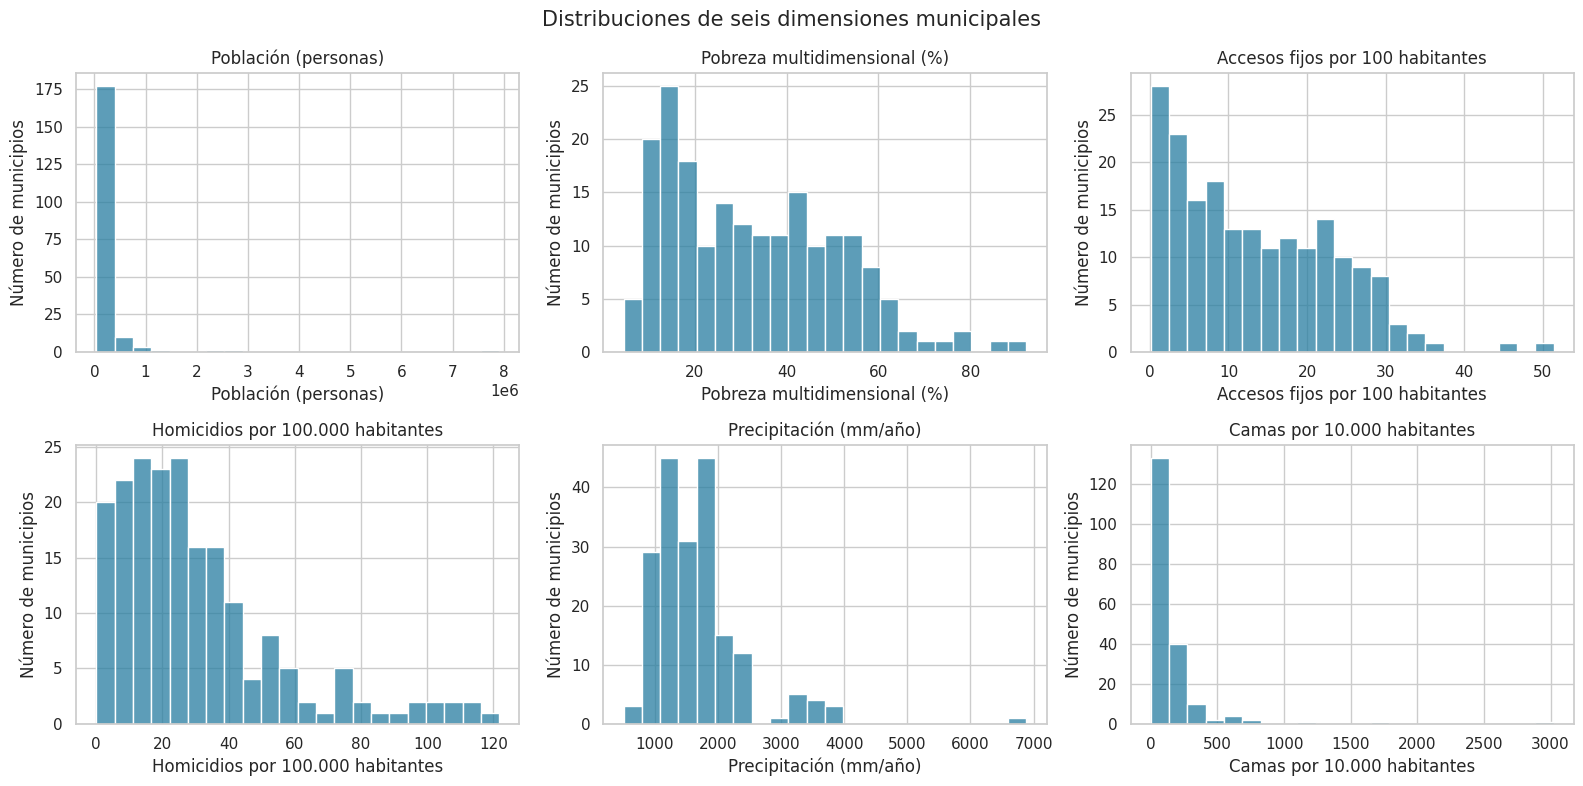

,municipios_fuera_de_bigotes
irca_2023,28
poblacion_total_2023,25
densidad_hab_km2_2023,24
incidencia_conflicto_armado_2022,19
ingresos_propios_percapita_millones_2023,17
camas_turisticas_por_10k_2026,16
precipitacion_anual_mm_2023,13
homicidios_por_100k_2024,13
establecimientos_turisticos_por_10k_2026,13
cobertura_neta_educacion_pct_2024,7


,municipio,departamento,poblacion_total_2023
40,BOGOTÁ. D.C.,BOGOTÁ. D.C.,7907281
19,MEDELLÍN,ANTIOQUIA,2595300
180,CALI,VALLE DEL CAUCA,2280522
34,BARRANQUILLA,ATLÁNTICO,1323551
42,CARTAGENA,BOLÍVAR,1052015
148,SAN JOSÉ DE CÚCUTA,NORTE DE SANTANDER,806378


In [4]:
graficar = [
    ('poblacion_total_2023', 'Población (personas)'),
    ('pobreza_multidimensional_pct_2018', 'Pobreza multidimensional (%)'),
    ('internet_fijo_por_100_hab_2023t3', 'Accesos fijos por 100 habitantes'),
    ('homicidios_por_100k_2024', 'Homicidios por 100.000 habitantes'),
    ('precipitacion_anual_mm_2023', 'Precipitación (mm/año)'),
    ('camas_turisticas_por_10k_2026', 'Camas por 10.000 habitantes')
]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (col, etiqueta) in zip(axes.flat, graficar):
    sns.histplot(X_original[col], bins=22, ax=ax, color='#277DA1')
    ax.set(title=etiqueta, xlabel=etiqueta, ylabel='Número de municipios')
fig.suptitle('Distribuciones de seis dimensiones municipales', fontsize=15)
plt.tight_layout()
plt.show()

q1, q3 = X_original.quantile(0.25), X_original.quantile(0.75)
iqr = q3 - q1
extremos = (X_original.lt(q1 - 1.5 * iqr) |
            X_original.gt(q3 + 1.5 * iqr))
conteo_extremos = extremos.sum().sort_values(ascending=False)
display(conteo_extremos.rename('municipios_fuera_de_bigotes').to_frame())
display(modelo.nlargest(6, 'poblacion_total_2023')
        [['municipio','departamento','poblacion_total_2023']])

**Resultado.** La población y algunas variables territoriales presentan una alta dispersión. Los valores extremos corresponden a municipios reales y se mantienen en el análisis.


### Correlación entre atributos

Se calcula la matriz de correlación para identificar variables que puedan estar aportando información similar.


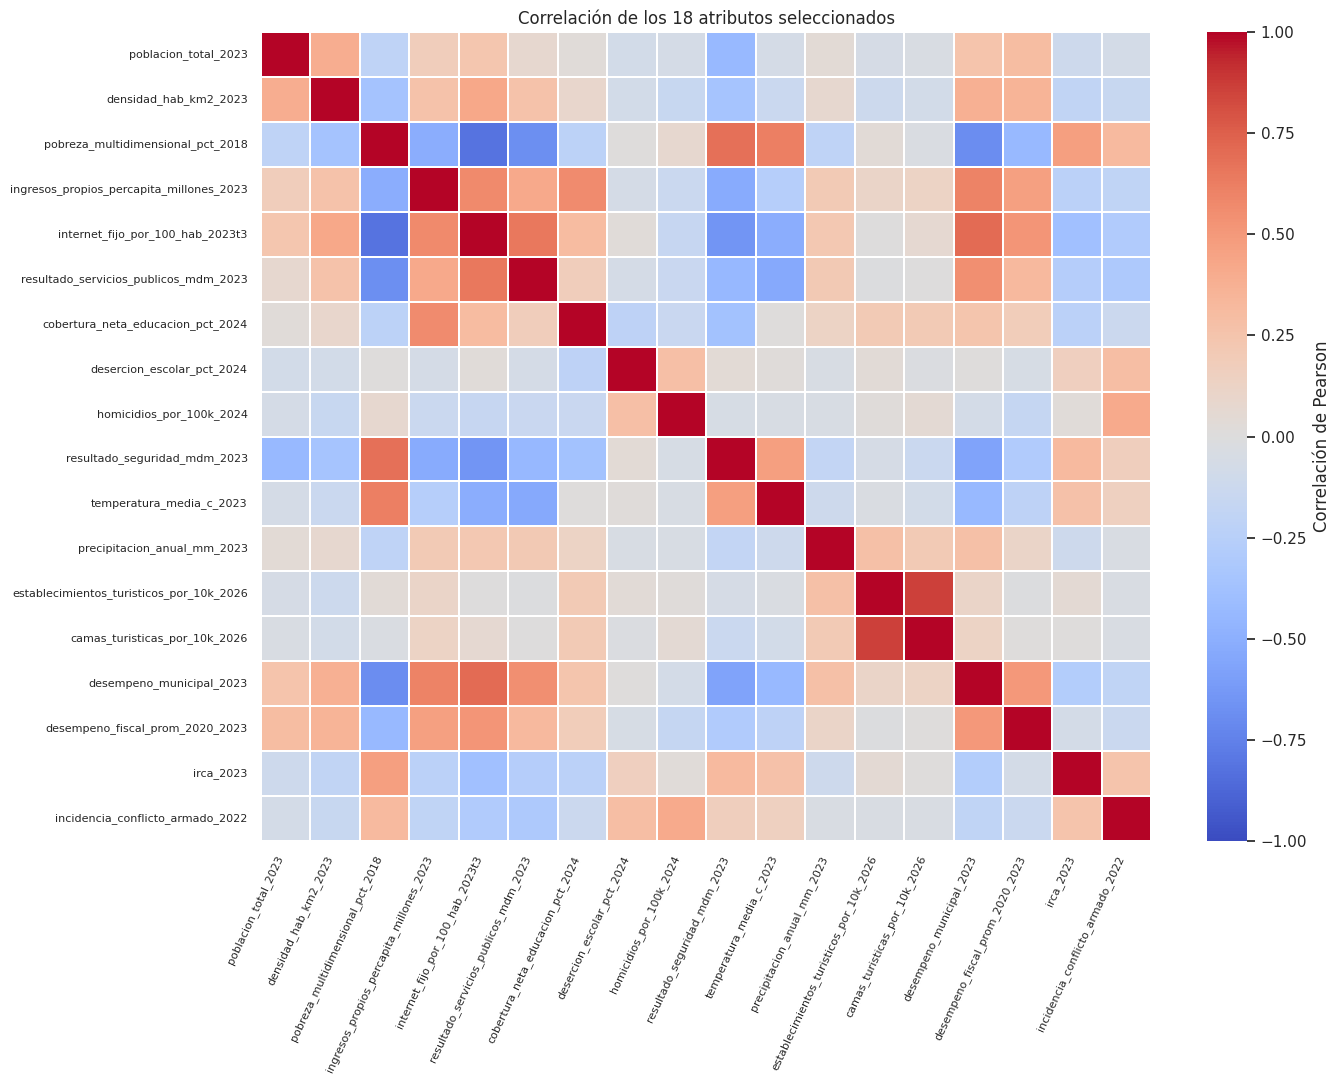

correlacion
establecimientos_turisticos_por_10k_2026 camas_turisticas_por_10k_2026                0.860
pobreza_multidimensional_pct_2018        internet_fijo_por_100_hab_2023t3            -0.817
internet_fijo_por_100_hab_2023t3         desempeno_municipal_2023                     0.706
pobreza_multidimensional_pct_2018        desempeno_municipal_2023                    -0.694
                                         resultado_servicios_publicos_mdm_2023       -0.687
                                         resultado_seguridad_mdm_2023                 0.683
internet_fijo_por_100_hab_2023t3         resultado_seguridad_mdm_2023                -0.655
                                         resultado_servicios_publicos_mdm_2023        0.654

In [5]:
correlacion = X_original.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(correlacion, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            linewidths=.25, cbar_kws={'label': 'Correlación de Pearson'})
plt.title('Correlación de los 18 atributos seleccionados')
plt.xticks(rotation=65, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout()
plt.show()
triangulo = correlacion.where(np.triu(np.ones(correlacion.shape), 1).astype(bool)).stack()
pares = triangulo.reindex(triangulo.abs().sort_values(ascending=False).index)
display(pares.head(8).rename('correlacion').round(3).to_frame())

**Resultado.** Establecimientos y camas turísticas presentan una correlación cercana a 0,86, mientras que pobreza e internet fijo muestran una asociación negativa fuerte. Estas relaciones se consideran al interpretar las distancias y los clusters.


## 5. Estandarización

Como las variables tienen escalas y unidades diferentes, se estandarizan antes de calcular distancias y aplicar clustering:

$$z_{ij}=\frac{x_{ij}-\bar{x}_j}{s_j}$$

Los valores originales se conservan para interpretar los resultados.


In [6]:
escalador = StandardScaler()
X_z = pd.DataFrame(escalador.fit_transform(X_original), columns=variables,
                   index=modelo.index)
assert X_z.shape == (len(modelo), 18)
resumen_escala = pd.DataFrame({'media_original': X_original.mean(),
                               'desviacion_original': X_original.std(ddof=0),
                               'media_z': X_z.mean(),
                               'desviacion_z': X_z.std(ddof=0)})
display(resumen_escala.round(3))

def indice_por_nombre(nombre):
    coincidencias = modelo.index[modelo['municipio'].astype(str).str.casefold()
                                 == nombre.casefold()].tolist()
    if len(coincidencias) != 1:
        raise ValueError(f'Nombre ausente o ambiguo: {nombre}. Usa DIVIPOLA.')
    return coincidencias[0]

i_bog = indice_por_nombre('BOGOTÁ. D.C.')
i_med = indice_por_nombre('MEDELLÍN')
comparacion_escala = pd.DataFrame({
    'diferencia_original_absoluta': (X_original.loc[i_bog]-X_original.loc[i_med]).abs(),
    'diferencia_estandarizada_absoluta': (X_z.loc[i_bog]-X_z.loc[i_med]).abs()
})
display(comparacion_escala.sort_values('diferencia_original_absoluta',
                                      ascending=False).head(8).round(2))

,media_original,desviacion_original,media_z,desviacion_z
poblacion_total_2023,198605.031,627073.079,-0.0,1.0
densidad_hab_km2_2023,697.484,1744.113,0.0,1.0
pobreza_multidimensional_pct_2018,32.532,18.200,0.0,1.0
ingresos_propios_percapita_millones_2023,0.551,0.632,-0.0,1.0
internet_fijo_por_100_hab_2023t3,13.383,10.004,0.0,1.0
resultado_servicios_publicos_mdm_2023,52.645,15.947,-0.0,1.0
cobertura_neta_educacion_pct_2024,89.628,14.647,-0.0,1.0
desercion_escolar_pct_2024,3.924,1.407,0.0,1.0
homicidios_por_100k_2024,30.426,25.275,0.0,1.0
resultado_seguridad_mdm_2023,84.426,10.045,0.0,1.0


,diferencia_original_absoluta,diferencia_estandarizada_absoluta
poblacion_total_2023,5311981.00,8.47
densidad_hab_km2_2023,2051.52,1.18
precipitacion_anual_mm_2023,138.99,0.19
camas_turisticas_por_10k_2026,85.42,0.30
resultado_servicios_publicos_mdm_2023,18.59,1.17
resultado_seguridad_mdm_2023,17.99,1.79
desempeno_fiscal_prom_2020_2023,5.91,0.80
pobreza_multidimensional_pct_2018,3.80,0.21


**Resultado.** Después de estandarizar, las diferencias se expresan en una escala comparable y ninguna variable domina únicamente por su unidad de medida.


## 6. Distancias y vecinos cercanos

Se comparan los municipios mediante distancia Euclidiana y Manhattan sobre las 18 variables estandarizadas:

$$d_E(a,b)=\sqrt{\sum_{j=1}^{18}(a_j-b_j)^2}, \qquad d_M(a,b)=\sum_{j=1}^{18}|a_j-b_j|$$

Una menor distancia representa mayor similitud según las variables seleccionadas; no corresponde a cercanía geográfica.


In [7]:
metricas = {'euclidean': 'euclidean', 'manhattan': 'cityblock'}
def resolver_municipio(nombre_municipio):
    texto = str(nombre_municipio).strip()
    if texto.isdigit():
        mascara = modelo['codigo_municipio'].eq(texto.zfill(5))
    else:
        mascara = modelo['municipio'].astype(str).str.casefold().eq(texto.casefold())
    indices = modelo.index[mascara].tolist()
    if len(indices) != 1:
        raise ValueError(f'Se esperó una coincidencia y se hallaron {len(indices)} para {texto!r}.')
    return indices[0]

def municipios_similares(nombre_municipio, metrica='euclidean', n=5):
    metrica = metrica.lower()
    if metrica not in metricas:
        raise ValueError('Usa metrica="euclidean" o metrica="manhattan".')
    if not 1 <= int(n) < len(modelo):
        raise ValueError(f'n debe estar entre 1 y {len(modelo)-1}.')
    i = resolver_municipio(nombre_municipio)
    distancias = cdist(X_z.iloc[[i]], X_z, metric=metricas[metrica]).ravel()
    distancias[i] = np.inf
    orden = np.argsort(distancias)[:int(n)]
    salida = modelo.loc[orden, ['codigo_municipio','municipio','departamento']].copy()
    salida.insert(0, 'ranking', range(1, len(salida)+1))
    salida['distancia'] = distancias[orden]
    return salida.reset_index(drop=True)

for consulta in ['BOGOTÁ. D.C.', 'LETICIA']:
    print(f'\n{consulta} — Euclidiana')
    display(municipios_similares(consulta, 'euclidean', 5).round(3))
    print(f'{consulta} — Manhattan')
    display(municipios_similares(consulta, 'manhattan', 5).round(3))


BOGOTÁ. D.C. — Euclidiana


,ranking,codigo_municipio,municipio,departamento,distancia
0,1,05001,MEDELLÍN,ANTIOQUIA,8.936
1,2,76001,CALI,VALLE DEL CAUCA,9.867
2,3,08001,BARRANQUILLA,ATLÁNTICO,11.378
3,4,68001,BUCARAMANGA,SANTANDER,12.129
4,5,13001,CARTAGENA,BOLÍVAR,12.423


BOGOTÁ. D.C. — Manhattan


,ranking,codigo_municipio,municipio,departamento,distancia
0,1,05001,MEDELLÍN,ANTIOQUIA,16.712
1,2,25473,MOSQUERA,CUNDINAMARCA,20.600
2,3,25286,FUNZA,CUNDINAMARCA,21.299
3,4,76001,CALI,VALLE DEL CAUCA,21.376
4,5,05266,ENVIGADO,ANTIOQUIA,21.653



LETICIA — Euclidiana


,ranking,codigo_municipio,municipio,departamento,distancia
0,1,23807,TIERRALTA,CÓRDOBA,3.145
1,2,13657,SAN JUAN NEPOMUCENO,BOLÍVAR,3.229
2,3,70713,SAN ONOFRE,SUCRE,3.253
3,4,23580,PUERTO LIBERTADOR,CÓRDOBA,3.336
4,5,20228,CURUMANÍ,CESAR,3.369


LETICIA — Manhattan


,ranking,codigo_municipio,municipio,departamento,distancia
0,1,23807,TIERRALTA,CÓRDOBA,9.268
1,2,20228,CURUMANÍ,CESAR,9.890
2,3,95001,SAN JOSÉ DEL GUAVIARE,GUAVIARE,10.194
3,4,23580,PUERTO LIBERTADOR,CÓRDOBA,10.570
4,5,05034,ANDES,ANTIOQUIA,10.588


**Resultado.** Bogotá tiene a Medellín como primer vecino con ambas métricas y Leticia a Tierralta. El resto del ranking cambia según la métrica, mostrando que la noción de similitud depende de cómo se agregan las diferencias.


### Explicación de la similitud

Para el vecino más cercano se identifican las variables con menor y mayor diferencia estandarizada, y se calcula su aporte a la distancia utilizada.


Vecino más cercano: MEDELLÍN (ANTIOQUIA); distancia 8.936
Características más parecidas (menor diferencia estandarizada):


,valor_consulta,valor_vecino,diferencia_z_absoluta,aporte_pct
incidencia_conflicto_armado_2022,1.373,1.705,0.024,0.001
irca_2023,0.533,1.116,0.045,0.003
desempeno_municipal_2023,80.251,79.586,0.055,0.004
internet_fijo_por_100_hab_2023t3,28.480,29.352,0.087,0.010
homicidios_por_100k_2024,15.353,11.906,0.136,0.023


Características que más los diferencian:


,valor_consulta,valor_vecino,diferencia_z_absoluta,aporte_pct
poblacion_total_2023,7907281.000,2595300.000,8.471,89.866
resultado_seguridad_mdm_2023,45.607,63.592,1.790,4.015
densidad_hab_km2_2023,4872.458,6923.977,1.176,1.733
resultado_servicios_publicos_mdm_2023,56.831,75.422,1.166,1.702
ingresos_propios_percapita_millones_2023,1.691,1.131,0.886,0.983


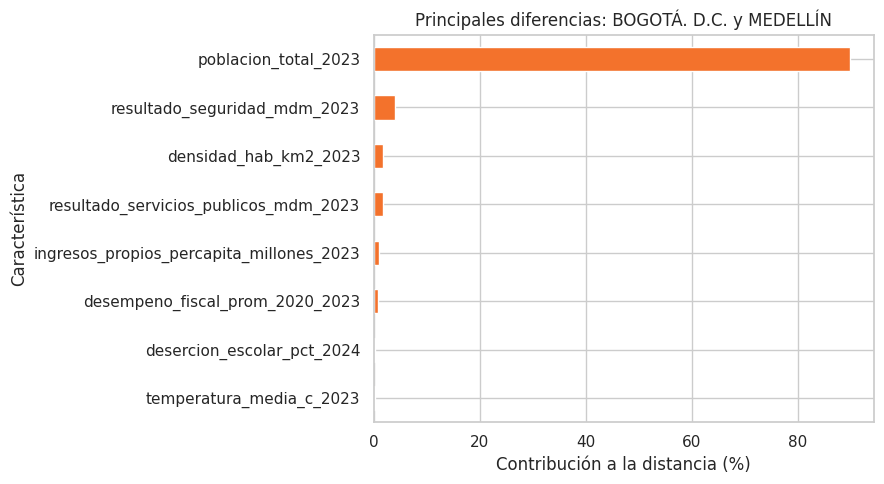

**Interpretación calculada.** BOGOTÁ. D.C. y MEDELLÍN se parecen especialmente en incidencia_conflicto_armado_2022, irca_2023, desempeno_municipal_2023. Sus mayores diferencias estandarizadas están en poblacion_total_2023, resultado_seguridad_mdm_2023. Una concordancia relativa no implica que todos sus indicadores sean buenos o malos.

In [8]:
def explicar_vecino(nombre_municipio, metrica='euclidean', mostrar=True):
    vecinos = municipios_similares(nombre_municipio, metrica, 1)
    i = resolver_municipio(nombre_municipio)
    j = resolver_municipio(vecinos.loc[0, 'codigo_municipio'])
    diferencia = (X_z.loc[i] - X_z.loc[j]).abs()
    aporte = diferencia.pow(2) if metrica == 'euclidean' else diferencia
    tabla = pd.DataFrame({
        'valor_consulta': X_original.loc[i],
        'valor_vecino': X_original.loc[j],
        'diferencia_z_absoluta': diferencia,
        'aporte_pct': 100 * aporte / aporte.sum()
    }).sort_values('diferencia_z_absoluta')
    parecidas = tabla.head(5)
    distintas = tabla.tail(5).iloc[::-1]
    if mostrar:
        print(f"Vecino más cercano: {modelo.loc[j, 'municipio']} "
              f"({modelo.loc[j, 'departamento']}); distancia {vecinos.loc[0, 'distancia']:.3f}")
        print('Características más parecidas (menor diferencia estandarizada):')
        display(parecidas.round(3))
        print('Características que más los diferencian:')
        display(distintas.round(3))
        fig, ax = plt.subplots(figsize=(9, 5))
        tabla.nlargest(8, 'aporte_pct').sort_values('aporte_pct')['aporte_pct'].plot.barh(
            ax=ax, color='#F3722C')
        ax.set(xlabel='Contribución a la distancia (%)', ylabel='Característica',
               title=f"Principales diferencias: {modelo.loc[i,'municipio']} y {modelo.loc[j,'municipio']}")
        plt.tight_layout(); plt.show()
        cercanas = ', '.join(parecidas.index[:3])
        lejanas = ', '.join(distintas.index[:2])
        display(Markdown(
            f"**Interpretación calculada.** {modelo.loc[i,'municipio']} y "
            f"{modelo.loc[j,'municipio']} se parecen especialmente en {cercanas}. "
            f"Sus mayores diferencias estandarizadas están en {lejanas}. "
            "Una concordancia relativa no implica que todos sus indicadores sean buenos o malos."
        ))
    return tabla

explicacion_bogota = explicar_vecino('BOGOTÁ. D.C.', 'euclidean')

**Resultado.** La comparación permite identificar qué variables sostienen la similitud entre dos municipios y cuáles explican sus principales diferencias.


## 7. Clustering jerárquico

Se aplica clustering jerárquico con método Ward sobre los datos estandarizados. El dendrograma muestra cómo se agrupan los municipios y la silhouette se usa como apoyo para escoger el número de clusters.


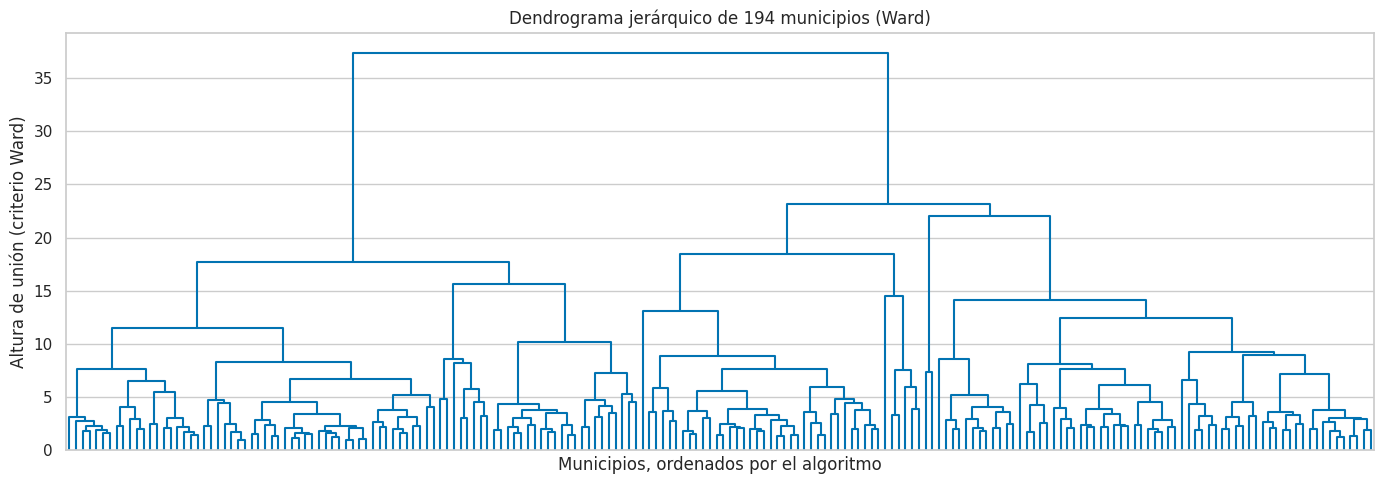

,k,silhouette,grupo_menor
0,2,0.194,85
1,3,0.138,42
2,4,0.132,2
3,5,0.134,2
4,6,0.119,2
5,7,0.127,2
6,8,0.130,1


K jerárquico elegido: 2


,municipios
cluster_jerarquico,
1,85
2,109


In [9]:
enlaces = linkage(X_z.to_numpy(), method='ward', metric='euclidean')
fig, ax = plt.subplots(figsize=(14, 5))
dendrogram(enlaces, no_labels=True, color_threshold=0, ax=ax)
ax.set(title='Dendrograma jerárquico de 194 municipios (Ward)',
       xlabel='Municipios, ordenados por el algoritmo',
       ylabel='Altura de unión (criterio Ward)')
plt.tight_layout(); plt.show()

evaluacion_jer = []
for k in range(2, 9):
    etiquetas = fcluster(enlaces, k, criterion='maxclust')
    evaluacion_jer.append({'k': k, 'silhouette': silhouette_score(X_z, etiquetas),
                           'grupo_menor': pd.Series(etiquetas).value_counts().min()})
evaluacion_jer = pd.DataFrame(evaluacion_jer)
k_jer = int(evaluacion_jer.loc[evaluacion_jer.silhouette.idxmax(), 'k'])
modelo['cluster_jerarquico'] = fcluster(enlaces, k_jer, criterion='maxclust')
display(evaluacion_jer.round(3))
print('K jerárquico elegido:', k_jer)
display(modelo['cluster_jerarquico'].value_counts().sort_index().rename('municipios').to_frame())

**Resultado.** La mejor silhouette en el rango evaluado se obtiene con dos clusters (aprox. 0,194), de 85 y 109 municipios. La separación existe, aunque no es fuerte.


### Perfil de los clusters

Se comparan medias y medianas en las unidades originales para describir las características de cada grupo.


poblacion_total_2023           densidad_hab_km2_2023  \
                                   mean    median                  mean   
cluster_jerarquico                                                        
1                              74236.40   56256.0                118.21   
2                             295589.74  102949.0               1149.21   

                           pobreza_multidimensional_pct_2018         \
                    median                              mean median   
cluster_jerarquico                                                    
1                    63.56                             47.80   46.0   
2                   373.69                             20.62   17.0   

                   ingresos_propios_percapita_millones_2023         \
                                                       mean median   
cluster_jerarquico                                                   
1                                                      0.21   0.18   
2                                                      0.82   0.61   

                   internet_fijo_por_100_hab_2023t3         \
                                               mean median   
cluster_jerarquico                                           
1                                              5.19   4.03   
2                                             19.77  19.79   

                   resultado_servicios_publicos_mdm_2023         \
                                                    mean median   
cluster_jerarquico                                                
1                                                  42.16  41.41   
2                                                  60.82  65.10   

                   cobertura_neta_educacion_pct_2024         \
                                                mean median   
cluster_jerarquico                                            
1                                              85.82  87.28   
2                                              92.60  90.97   

                   desercion_escolar_pct_2024        homicidios_por_100k_2024  \
                                         mean median                     mean   
cluster_jerarquico                                                              
1                                        3.89   3.55                    29.05   
2                                        3.95   3.92                    31.50   

                          resultado_seguridad_mdm_2023         \
                   median                         mean median   
cluster_jerarquico                                              
1                   23.88                        91.56  91.86   
2                   23.13                        78.87  81.21   

                   temperatura_media_c_2023         \
                                       mean median   
cluster_jerarquico                                   
1                                     25.27  27.68   
2                                     20.25  18.87   

                   precipitacion_anual_mm_2023           \
                                          mean   median   
cluster_jerarquico                                        
1                                      1307.87  1288.91   
2                                      1952.26  1779.59   

                   establecimientos_turisticos_por_10k_2026         \
                                                       mean median   
cluster_jerarquico                                                   
1                                                      3.14   1.98   
2                                                      5.69   3.63   

                   camas_turisticas_por_10k_2026          \
                                            mean  median   
cluster_jerarquico                                         
1                                          89.99   50.68   
2                                         197.47  110.57   

                   des

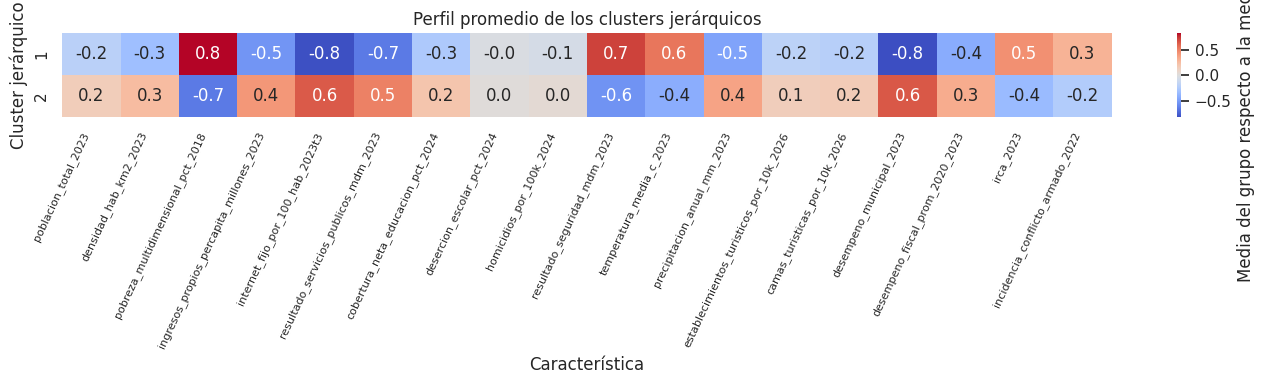

Cluster 1: valores relativos mayores en pobreza_multidimensional_pct_2018, resultado_seguridad_mdm_2023, temperatura_media_c_2023; menores en desempeno_municipal_2023, internet_fijo_por_100_hab_2023t3, resultado_servicios_publicos_mdm_2023.
Cluster 2: valores relativos mayores en desempeno_municipal_2023, internet_fijo_por_100_hab_2023t3, resultado_servicios_publicos_mdm_2023; menores en pobreza_multidimensional_pct_2018, resultado_seguridad_mdm_2023, temperatura_media_c_2023.


,pobreza_multidimensional_pct_2018,internet_fijo_por_100_hab_2023t3,desempeno_municipal_2023,homicidios_por_100k_2024,temperatura_media_c_2023,irca_2023
cluster_jerarquico,,,,,,
1,47.80,5.19,49.75,29.05,25.27,13.74
2,20.62,19.77,67.57,31.50,20.25,3.25


In [10]:
perfil_jer = modelo.groupby('cluster_jerarquico')[variables].agg(['mean','median'])
display(perfil_jer.round(2))

medias_jer = modelo.groupby('cluster_jerarquico')[variables].mean()
medias_globales = X_original.mean()
desv_globales = X_original.std(ddof=0)
desviacion_perfil = (medias_jer - medias_globales) / desv_globales
fig, ax = plt.subplots(figsize=(14, 4))
sns.heatmap(desviacion_perfil, cmap='coolwarm', center=0, annot=True, fmt='.1f',
            cbar_kws={'label':'Media del grupo respecto a la media general (DE)'}, ax=ax)
ax.set(title='Perfil promedio de los clusters jerárquicos',
       xlabel='Característica', ylabel='Cluster jerárquico')
plt.xticks(rotation=65, ha='right', fontsize=8)
plt.tight_layout(); plt.show()

for grupo in medias_jer.index:
    arriba = desviacion_perfil.loc[grupo].nlargest(3).index.tolist()
    abajo = desviacion_perfil.loc[grupo].nsmallest(3).index.tolist()
    print(f'Cluster {grupo}: valores relativos mayores en {", ".join(arriba)}; '
          f'menores en {", ".join(abajo)}.')

resumen_clave = modelo.groupby('cluster_jerarquico')[[
    'pobreza_multidimensional_pct_2018', 'internet_fijo_por_100_hab_2023t3',
    'desempeno_municipal_2023', 'homicidios_por_100k_2024',
    'temperatura_media_c_2023', 'irca_2023'
]].mean().round(2)
display(resumen_clave)

**Resultado.** Los dos grupos se diferencian principalmente en pobreza multidimensional, acceso a internet, desempeño municipal y temperatura promedio. La tasa de homicidios por sí sola no separa claramente los clusters.


## 8. K-Means

Se aplica K-Means sobre los datos estandarizados y se comparan distintos valores de $k$ mediante el método del codo y la silhouette.


,k,inercia,silhouette,grupo_menor
0,2,2722.785,0.223,83
1,3,2490.524,0.149,36
2,4,2236.878,0.155,2
3,5,2061.743,0.150,2
4,6,1883.865,0.160,2
5,7,1778.555,0.166,2
6,8,1679.702,0.156,1


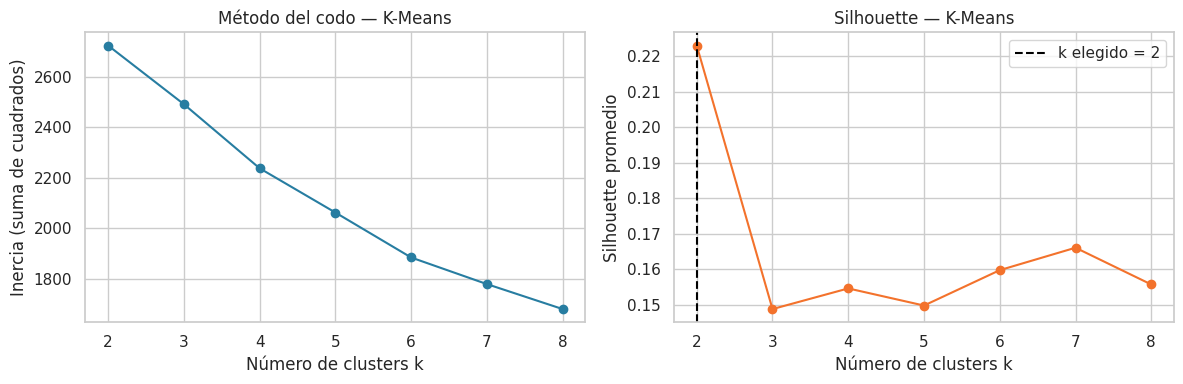

K-Means elegido: 2


,municipios
cluster_kmeans,
0,111
1,83


cluster_kmeans,0,1
cluster_jerarquico,,
1,84,1
2,27,82


Índice de Rand ajustado (ARI): 0.503


In [11]:
evaluacion_km = []
modelos_km = {}
for k in range(2, 9):
    ajuste = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=20)
    etiquetas = ajuste.fit_predict(X_z)
    modelos_km[k] = ajuste
    evaluacion_km.append({'k': k, 'inercia': ajuste.inertia_,
                          'silhouette': silhouette_score(X_z, etiquetas),
                          'grupo_menor': pd.Series(etiquetas).value_counts().min()})
evaluacion_km = pd.DataFrame(evaluacion_km)
k_km = int(evaluacion_km.loc[evaluacion_km.silhouette.idxmax(), 'k'])
modelo['cluster_kmeans'] = modelos_km[k_km].labels_
display(evaluacion_km.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(evaluacion_km.k, evaluacion_km.inercia, 'o-', color='#277DA1')
axes[0].set(title='Método del codo — K-Means', xlabel='Número de clusters k',
            ylabel='Inercia (suma de cuadrados)')
axes[1].plot(evaluacion_km.k, evaluacion_km.silhouette, 'o-', color='#F3722C')
axes[1].axvline(k_km, ls='--', color='black', label=f'k elegido = {k_km}')
axes[1].set(title='Silhouette — K-Means', xlabel='Número de clusters k',
            ylabel='Silhouette promedio')
axes[1].legend()
plt.tight_layout(); plt.show()

print('K-Means elegido:', k_km)
display(modelo['cluster_kmeans'].value_counts().sort_index().rename('municipios').to_frame())
comparacion_metodos = pd.crosstab(modelo.cluster_jerarquico, modelo.cluster_kmeans)
display(comparacion_metodos)
ari = adjusted_rand_score(modelo.cluster_jerarquico, modelo.cluster_kmeans)
print('Índice de Rand ajustado (ARI):', round(ari, 3))

**Resultado.** K-Means también favorece dos clusters, con silhouette aproximada de 0,223 y grupos de 111 y 83 municipios. El acuerdo con el clustering jerárquico es parcial (ARI ≈ 0,503).


### Perfil de K-Means

Se describen los grupos usando las variables en su escala original.


In [12]:
perfil_km = modelo.groupby('cluster_kmeans')[variables].agg(['mean','median'])
display(perfil_km.round(2))
display(modelo.groupby('cluster_kmeans')[[
    'pobreza_multidimensional_pct_2018', 'internet_fijo_por_100_hab_2023t3',
    'homicidios_por_100k_2024', 'desempeno_municipal_2023',
    'temperatura_media_c_2023', 'irca_2023'
]].mean().round(2))

poblacion_total_2023           densidad_hab_km2_2023          \
                               mean    median                  mean  median   
cluster_kmeans                                                                
0                          86184.97   56256.0                145.23   67.96   
1                         348949.93  130362.0               1436.04  494.55   

               pobreza_multidimensional_pct_2018         \
                                            mean median   
cluster_kmeans                                            
0                                          44.70   43.8   
1                                          16.26   15.1   

               ingresos_propios_percapita_millones_2023         \
                                                   mean median   
cluster_kmeans                                                   
0                                                  0.26   0.22   
1                                                  0.95   0.66   

               internet_fijo_por_100_hab_2023t3         \
                                           mean median   
cluster_kmeans                                           
0                                          6.68   6.03   
1                                         22.35  22.45   

               resultado_servicios_publicos_mdm_2023         \
                                                mean median   
cluster_kmeans                                                
0                                              44.30  43.16   
1                                              63.81  66.73   

               cobertura_neta_educacion_pct_2024         \
                                            mean median   
cluster_kmeans                                            
0                                          85.67  86.78   
1                                          94.92  92.95   

               desercion_escolar_pct_2024        homicidios_por_100k_2024  \
                                     mean median                     mean   
cluster_kmeans                                                              
0                                    3.95   3.55                    34.72   
1                                    3.89   3.92                    24.69   

                      resultado_seguridad_mdm_2023         \
               median                         mean median   
cluster_kmeans                                              
0               25.61                        90.10  90.85   
1               21.11                        76.84  79.24   

               temperatura_media_c_2023        precipitacion_anual_mm_2023  \
                                   mean median                        mean   
cluster_kmeans                                                               
0                                 24.84  26.63                     1507.35   
1                                 19.25  18.86                     1887.35   

                        establecimientos_turisticos_por_10k_2026         \
                 median                                     mean median   
cluster_kmeans                                                            
0               1321.17                                     3.56   2.24   
1               1807.33                                     5.92   3.67   

               camas_turisticas_por_10k_2026         desempeno_municipal_2023  \
                                        mean  median                     mean   
cluster_kmeans                                                                  
0                                     106.34   57.12                    51.93   
1                                     209.27  122.31                    70.24   

                      desempeno_fiscal_prom_2020_2023        irca_2023         \
               median                            mean median      mean median   
cluster_kmeans                                                

,pobreza_multidimensional_pct_2018,internet_fijo_por_100_hab_2023t3,homicidios_por_100k_2024,desempeno_municipal_2023,temperatura_media_c_2023,irca_2023
cluster_kmeans,,,,,,
0,44.70,6.68,34.72,51.93,24.84,11.65
1,16.26,22.35,24.69,70.24,19.25,2.76


**Resultado.** El grupo 0 presenta en promedio mayor pobreza multidimensional y menor acceso a internet que el grupo 1, además de diferencias en desempeño municipal.


## 9. Visualización en dos dimensiones

Se utiliza PCA únicamente para proyectar los municipios en dos dimensiones y visualizar los clusters obtenidos.


Varianza explicada por PC1 y PC2: [0.313 0.117] | total: 0.43


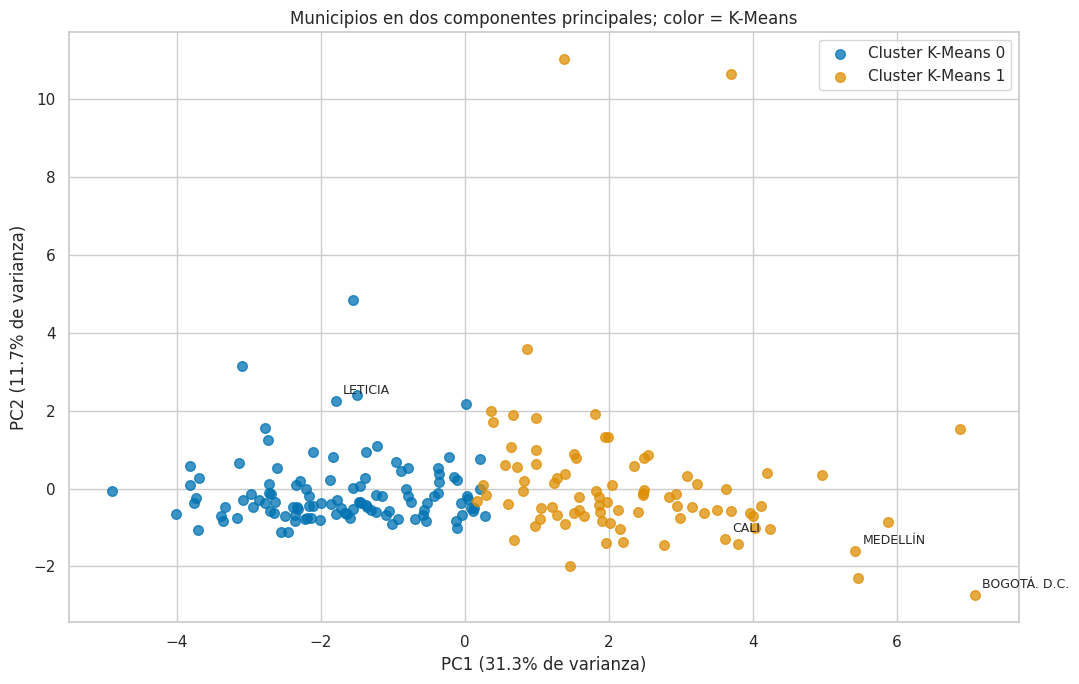

In [13]:
pca = PCA(n_components=2)
coordenadas_pca = pca.fit_transform(X_z)
modelo['PC1'], modelo['PC2'] = coordenadas_pca[:,0], coordenadas_pca[:,1]
print('Varianza explicada por PC1 y PC2:',
      np.round(pca.explained_variance_ratio_, 3),
      '| total:', round(pca.explained_variance_ratio_.sum(), 3))

fig, ax = plt.subplots(figsize=(11, 7))
for grupo in sorted(modelo.cluster_kmeans.unique()):
    m = modelo.cluster_kmeans.eq(grupo)
    ax.scatter(modelo.loc[m,'PC1'], modelo.loc[m,'PC2'],
               s=48, alpha=.76, label=f'Cluster K-Means {grupo}')
for nombre in ['BOGOTÁ. D.C.', 'MEDELLÍN', 'CALI', 'LETICIA']:
    i = resolver_municipio(nombre)
    ax.annotate(nombre, (modelo.loc[i,'PC1'], modelo.loc[i,'PC2']),
                xytext=(5,5), textcoords='offset points', fontsize=9)
ax.set(xlabel=f'PC1 ({100*pca.explained_variance_ratio_[0]:.1f}% de varianza)',
       ylabel=f'PC2 ({100*pca.explained_variance_ratio_[1]:.1f}% de varianza)',
       title='Municipios en dos componentes principales; color = K-Means')
ax.legend()
plt.tight_layout(); plt.show()

**Resultado.** Los dos componentes explican cerca del 43% de la variación total. La gráfica permite observar una separación parcial, pero las distancias del análisis se mantienen en las 18 dimensiones originales.


## 10. Exportación y reproducibilidad

Se exportan las asignaciones de cluster y se comprueba que el análisis conserve los requisitos y la estructura esperada.


In [14]:
salida_clusters = datos[['codigo_municipio','municipio','departamento']].copy()
etiquetas_exportar = modelo[['codigo_municipio','cluster_jerarquico','cluster_kmeans']]
salida_clusters = salida_clusters.merge(etiquetas_exportar,
                                      on='codigo_municipio', how='left', validate='one_to_one')
salida_clusters['estado_modelado'] = np.where(
    salida_clusters.cluster_kmeans.notna(), 'Incluido',
    'Excluido: indicador no numérico en una de las 18 variables')
salida_clusters.to_csv('municipios_con_clusters.csv', index=False, encoding='utf-8-sig')

assert len(datos) == 200 and len(modelo) == 194 and len(variables) == 18
assert fuentes.institucion.nunique() >= 3
assert salida_clusters.codigo_municipio.is_unique
assert salida_clusters.cluster_kmeans.notna().sum() == 194
assert salida_clusters.cluster_kmeans.isna().sum() == 6
assert resolver_municipio(municipios_similares('BOGOTÁ. D.C.', n=1)
                         .loc[0,'codigo_municipio']) != i_bog
assert abs(X_z.mean().to_numpy()).max() < 1e-10
print('Comprobaciones superadas. Archivo generado: municipios_con_clusters.csv')
display(salida_clusters.head())

Comprobaciones superadas. Archivo generado: municipios_con_clusters.csv


,codigo_municipio,municipio,departamento,cluster_jerarquico,cluster_kmeans,estado_modelado
0,91001,LETICIA,AMAZONAS,1.0,0.0,Incluido
1,05034,ANDES,ANTIOQUIA,2.0,0.0,Incluido
2,05045,APARTADÓ,ANTIOQUIA,2.0,1.0,Incluido
3,05079,BARBOSA,ANTIOQUIA,2.0,1.0,Incluido
4,05088,BELLO,ANTIOQUIA,2.0,1.0,Incluido


**Resultado.** El archivo exportado conserva los 200 municipios originales, con 194 asignaciones de cluster y seis exclusiones por datos no numéricos.


## 11. Limitaciones

- Los indicadores provienen de distintos años entre 2018 y 2026, por lo que no representan un único momento temporal.
- Los 200 municipios fueron seleccionados por población y no constituyen una muestra aleatoria de todos los municipios del país.
- Seis municipios se excluyen del modelado por valores `N.D.` en IRCA.
- Algunas variables están correlacionadas, por lo que ciertas dimensiones pueden tener mayor peso conjunto.
- Temperatura y precipitación de NASA POWER corresponden a un punto representativo del municipio.
- Los resultados dependen de las variables elegidas, el escalamiento, la métrica y el método de agrupamiento; similitud estadística no implica causalidad ni cercanía geográfica.


## 12. Conclusiones

- Se obtuvo una representación de 194 municipios mediante 18 variables provenientes de varias fuentes institucionales.
- Las distancias Euclidiana y Manhattan permiten encontrar municipios con perfiles similares, aunque el ranking puede cambiar según la métrica.
- Tanto Ward como K-Means favorecen dos grupos, pero las silhouette obtenidas indican una separación moderada y no categorías rígidas.
- Pobreza multidimensional, conectividad y desempeño municipal aparecen entre las variables que más diferencian los perfiles encontrados.
- La representación resulta útil para explorar municipios comparables y patrones territoriales, teniendo en cuenta las limitaciones de años, muestra y selección de variables.


## 13. Explorador interactivo

Se incorpora una interfaz en Gradio para consultar un municipio, sus vecinos más cercanos, la comparación de variables y el cluster asignado a partir de los resultados ya calculados.


In [15]:
import importlib.util
import sys
if 'google.colab' in sys.modules or importlib.util.find_spec('gradio') is None:
    get_ipython().run_cell('!pip install -q gradio')
import gradio as gr
print('Gradio', gr.__version__)

Gradio 6.29.0


In [16]:
ETIQUETAS = {
    'poblacion_total_2023': 'Población total',
    'densidad_hab_km2_2023': 'Densidad (hab/km²)',
    'pobreza_multidimensional_pct_2018': 'Pobreza multidimensional (%)',
    'ingresos_propios_percapita_millones_2023': 'Ingresos propios (millones COP/hab.)',
    'internet_fijo_por_100_hab_2023t3': 'Internet fijo (por 100 hab.)',
    'resultado_servicios_publicos_mdm_2023': 'Servicios públicos (MDM)',
    'cobertura_neta_educacion_pct_2024': 'Cobertura neta educativa (%)',
    'desercion_escolar_pct_2024': 'Deserción escolar (%)',
    'homicidios_por_100k_2024': 'Homicidios (por 100.000 hab.)',
    'resultado_seguridad_mdm_2023': 'Seguridad (MDM)',
    'temperatura_media_c_2023': 'Temperatura media (°C)',
    'precipitacion_anual_mm_2023': 'Precipitación anual (mm)',
    'establecimientos_turisticos_por_10k_2026': 'Alojamientos (por 10.000 hab.)',
    'camas_turisticas_por_10k_2026': 'Camas turísticas (por 10.000 hab.)',
    'desempeno_municipal_2023': 'Desempeño municipal (MDM)',
    'desempeno_fiscal_prom_2020_2023': 'Desempeño fiscal (prom. 2020–2023)',
    'irca_2023': 'Riesgo de calidad del agua (IRCA)',
    'incidencia_conflicto_armado_2022': 'Incidencia del conflicto armado'
}
assert set(ETIQUETAS) == set(variables)

medias_cluster = perfil_km.xs('mean', axis=1, level=1)
medianas_cluster = perfil_km.xs('median', axis=1, level=1)
tamano_cluster = modelo['cluster_kmeans'].value_counts()
desviacion_cluster = (medias_cluster - X_original.mean()) / X_original.std(ddof=0)
cluster_por_codigo = modelo.set_index('codigo_municipio')['cluster_kmeans']

opciones_gradio = sorted(
    [(f"{fila.municipio} ({fila.departamento}) · {fila.codigo_municipio}",
      fila.codigo_municipio) for fila in modelo.itertuples()],
    key=lambda par: par[0]
)

def frase_variables(tabla, columna):
    return ', '.join(
        f"{ETIQUETAS[variable]} (|Δz| = {fila.diferencia_z_absoluta:.2f})"
        for variable, fila in tabla.iterrows()
    )

def grafico_comparacion(i, j, aportes):
    destacadas = list(aportes.nlargest(6, 'aporte_pct').index)
    for variable in aportes.nsmallest(2, 'diferencia_z_absoluta').index:
        if variable not in destacadas:
            destacadas.append(variable)
    etiquetas = [ETIQUETAS[v] for v in destacadas]
    y = np.arange(len(destacadas))
    fig, ax = plt.subplots(figsize=(10, 5.5))
    ax.barh(y - .18, X_z.loc[i, destacadas], height=.35,
            label=str(modelo.loc[i, 'municipio']), color='#2563eb')
    ax.barh(y + .18, X_z.loc[j, destacadas], height=.35,
            label=str(modelo.loc[j, 'municipio']), color='#f59e0b')
    ax.set_yticks(y, etiquetas)
    ax.invert_yaxis()
    ax.axvline(0, color='#475569', lw=.9)
    ax.set(xlabel='Valor estandarizado (desviaciones estándar)',
           ylabel='Característica',
           title='Municipio seleccionado vs. vecino más cercano')
    ax.legend(loc='best', title='Municipio')
    fig.tight_layout()
    return fig

def grafico_contribuciones(aportes, metrica):
    principales = aportes.nlargest(6, 'aporte_pct').iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.barh([ETIQUETAS[v] for v in principales.index],
            principales['aporte_pct'], color='#0f766e')
    base = 'd² euclidiana' if metrica == 'euclidean' else 'd Manhattan'
    ax.set(xlabel=f'Contribución al total de {base} (%)',
           ylabel='Característica', title='Mayores contribuciones a la diferencia')
    fig.tight_layout()
    return fig

def analizar_municipio(codigo, metrica, n):
    i = resolver_municipio(codigo)
    fila = modelo.loc[i]
    vecinos = municipios_similares(codigo, metrica, int(n))
    vecino = vecinos.iloc[0]
    j = resolver_municipio(vecino['codigo_municipio'])
    aportes = explicar_vecino(codigo, metrica, mostrar=False)
    grupo = int(fila['cluster_kmeans'])

    perfil = (
        f"### {fila['municipio']} · {fila['departamento']}\n"
        f"**DIVIPOLA:** {fila['codigo_municipio']}  ·  "
        f"**Población (2023):** {fila['poblacion_total_2023']:,.0f} habitantes  ·  "
        f"**Cluster K-Means:** {grupo}  ·  "
        f"**Cluster Ward:** {int(fila['cluster_jerarquico'])}\n\n"
        f"**Pobreza multidimensional (2018):** "
        f"{fila['pobreza_multidimensional_pct_2018']:.1f}%  ·  "
        f"**Internet fijo (2023-T3):** "
        f"{fila['internet_fijo_por_100_hab_2023t3']:.1f} por 100 habitantes  ·  "
        f"**Cobertura neta educativa (2024):** "
        f"{fila['cobertura_neta_educacion_pct_2024']:.1f}%"
    )

    tabla_vecinos = vecinos[['ranking', 'municipio', 'departamento', 'distancia']].copy()
    tabla_vecinos['cluster'] = vecinos['codigo_municipio'].map(cluster_por_codigo).astype(int)
    tabla_vecinos['distancia'] = tabla_vecinos['distancia'].round(3)
    tabla_vecinos.columns = ['Ranking', 'Municipio', 'Departamento',
                             'Distancia', 'Cluster K-Means']

    parecidas = aportes.nsmallest(3, 'diferencia_z_absoluta')
    diferentes = aportes.nlargest(3, 'diferencia_z_absoluta')
    nombre_consulta = str(fila['municipio'])
    nombre_vecino = str(modelo.loc[j, 'municipio'])
    nombre_metrica = 'euclidiana' if metrica == 'euclidean' else 'Manhattan'
    explicacion = (
        f"### ¿Por qué aparece este vecino?\n"
        f"El municipio más similar a **{nombre_consulta}** es "
        f"**{nombre_vecino} ({modelo.loc[j, 'departamento']})**, "
        f"con distancia {nombre_metrica} **{vecino['distancia']:.3f}**.\n\n"
        f"**Tres características más parecidas:** {frase_variables(parecidas, 'diferencia_z_absoluta')}.\n\n"
        f"**Tres mayores diferencias:** {frase_variables(diferentes, 'diferencia_z_absoluta')}.\n\n"
        "Las comparaciones usan diferencias absolutas entre valores estandarizados; "
        "similitud no implica cercanía geográfica ni causalidad."
    )

    contraste = desviacion_cluster.loc[grupo]
    altas = contraste.nlargest(3).index
    bajas = contraste.nsmallest(3).index
    caracteristicas = pd.concat([medias_cluster.loc[grupo, list(altas)],
                                  medias_cluster.loc[grupo, list(bajas)]])
    tabla_cluster = pd.DataFrame({
        'Característica': [ETIQUETAS[v] for v in caracteristicas.index],
        'Media del cluster (unidad original)': caracteristicas.to_numpy().round(2),
        'Mediana del cluster (unidad original)':
            medianas_cluster.loc[grupo, caracteristicas.index].to_numpy().round(2),
        'Contraste frente a la muestra (z)':
            contraste.loc[caracteristicas.index].to_numpy().round(2)
    })
    resumen = (
        f"### Cluster K-Means {grupo}\n"
        f"**{int(tamano_cluster.loc[grupo])} municipios** de los "
        f"{len(modelo)} con datos completos pertenecen a este grupo.\n\n"
        f"**Promedios relativamente altos:** {', '.join(ETIQUETAS[v] for v in altas)}.\n\n"
        f"**Promedios relativamente bajos:** {', '.join(ETIQUETAS[v] for v in bajas)}.\n\n"
        "La tabla muestra los valores medios y medianos en sus unidades originales; "
        "el contraste *z* solo ordena qué distingue al grupo de la muestra. "
        "No es una clasificación de calidad de vida."
    )
    return (perfil, tabla_vecinos, explicacion,
            grafico_comparacion(i, j, aportes),
            grafico_contribuciones(aportes, metrica), resumen, tabla_cluster)

In [17]:
pruebas_panel = [
    ('11001', 'euclidean', 3),
    ('05001', 'manhattan', 5),
    ('91001', 'euclidean', 10),
    ('11001', 'manhattan', 7),
]
rankings_probados = []
comparaciones_probadas = []
for codigo_prueba, metrica_prueba, n_prueba in pruebas_panel:
    salidas = analizar_municipio(codigo_prueba, metrica_prueba, n_prueba)
    ranking_esperado = municipios_similares(codigo_prueba, metrica_prueba, n_prueba)
    assert len(salidas[1]) == n_prueba
    np.testing.assert_allclose(salidas[1]['Distancia'],
                               ranking_esperado['distancia'].round(3))
    assert salidas[1]['Municipio'].tolist() == ranking_esperado['municipio'].tolist()
    rankings_probados.append(tuple(salidas[1]['Municipio']))
    assert f"Cluster K-Means:** {int(modelo.loc[resolver_municipio(codigo_prueba), 'cluster_kmeans'])}" in salidas[0]
    diferencia_esperada = explicar_vecino(codigo_prueba, metrica_prueba, mostrar=False)
    for v in diferencia_esperada.nlargest(3, 'diferencia_z_absoluta').index:
        assert ETIQUETAS[v] in salidas[2]
    for v in diferencia_esperada.nsmallest(3, 'diferencia_z_absoluta').index:
        assert ETIQUETAS[v] in salidas[2]
    comparaciones_probadas.append(tuple(round(p.get_width(), 4)
                                      for p in salidas[3].axes[0].patches))
    for figura in (salidas[3], salidas[4]):
        assert len(figura.axes) == 1 and len(figura.axes[0].patches) >= 6
        plt.close(figura)
    print(f"OK: {modelo.loc[resolver_municipio(codigo_prueba), 'municipio']} · "
          f"{metrica_prueba} · {n_prueba} vecinos · cluster verificado")
assert len(set(rankings_probados)) >= 3
assert len(set(comparaciones_probadas)) >= 3
print('Las cuatro pruebas de contenido del panel finalizaron sin errores.')

OK: BOGOTÁ. D.C. · euclidean · 3 vecinos · cluster verificado
OK: MEDELLÍN · manhattan · 5 vecinos · cluster verificado
OK: LETICIA · euclidean · 10 vecinos · cluster verificado
OK: BOGOTÁ. D.C. · manhattan · 7 vecinos · cluster verificado
Las cuatro pruebas de contenido del panel finalizaron sin errores.


In [21]:
with gr.Blocks(title='Explorador de Municipios de Colombia') as demo:
    gr.Markdown('# Explorador de Municipios de Colombia')
    gr.Markdown('**¿Qué municipios se parecen para vivir y desarrollarse?** '
                'Explora 18 indicadores y dos formas de medir distancia. '
                'Los clusters y el escalamiento proceden del análisis anterior.')
    with gr.Row():
        seleccion = gr.Dropdown(choices=opciones_gradio,
                                value=modelo.loc[i_bog, 'codigo_municipio'],
                                label='Municipio', scale=3)
        metrica_ui = gr.Dropdown(choices=[('Euclidiana', 'euclidean'),
                                          ('Manhattan', 'manhattan')],
                                 value='euclidean', label='Métrica', scale=1)
        numero = gr.Slider(minimum=1, maximum=10, step=1, value=5,
                           label='Número de vecinos', scale=1)
    analizar = gr.Button('Analizar municipio', variant='primary', size='lg')
    with gr.Tabs():
        with gr.Tab('🤝 Municipios similares'):
            salida_vecinos = gr.Dataframe(label='Ranking de vecinos', interactive=False)
            salida_explicacion = gr.Markdown()
            salida_aportes = gr.Plot(label='Contribución a la distancia')
        with gr.Tab('📍 Perfil'):
            salida_perfil = gr.Markdown('Selecciona un municipio y pulsa **Analizar municipio**.')
        with gr.Tab('📊 Comparación'):
            salida_comparacion = gr.Plot(label='Perfiles estandarizados')
        with gr.Tab('🧩 Cluster'):
            salida_cluster = gr.Markdown()
            salida_tabla_cluster = gr.Dataframe(label='Perfil del cluster en unidades originales',
                                                 interactive=False)
    analizar.click(fn=analizar_municipio,
                   inputs=[seleccion, metrica_ui, numero],
                   outputs=[salida_perfil, salida_vecinos, salida_explicacion,
                            salida_comparacion, salida_aportes, salida_cluster,
                            salida_tabla_cluster])

import sys
if 'google.colab' in sys.modules:
    demo.launch(inline=True, height=850, show_error=True,
                theme=gr.themes.Soft(primary_hue='blue', neutral_hue='slate'))
else:
    demo.launch(inline=False, share=False, prevent_thread_lock=True,
                show_error=True,
                theme=gr.themes.Soft(primary_hue='blue', neutral_hue='slate'))
    from urllib.request import urlopen
    with urlopen(demo.local_url, timeout=10) as respuesta:
        assert respuesta.status == 200
    print('Página local de Gradio accesible (HTTP 200).')

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://eaa1593d5e557731ca.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
